Using DeepVelo and Cell rank to create Transistion Matrixes



In [12]:
# Importa that will be used

import cellrank as cr
import scanpy as sc 
import scvelo as scv 
import session_info
from deepvelo.utils import (
    velocity,
    velocity_confidence,
    continuity_confidence,
    update_dict,
    cross_boundary_correctness,
)
from deepvelo.utils.scatter import scatter
from deepvelo.utils.preprocess import autoset_coeff_s
from deepvelo.utils.plot import statplot, compare_plot
from deepvelo import train, Constants

cr.settings.logging_level = 3

c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\deepvelo\utils\scatter.py:5: DeprecationWarning: deepvelo.utils.scatter is deprecated. Please use deepvelo.plot.scatter instead.
  warnings.warn(
c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\deepvelo\utils\plot.py:5: DeprecationWarning: deepvelo.utils.plot is deprecated. Please use deepvelo.plot.plot instead.
  warnings.warn(


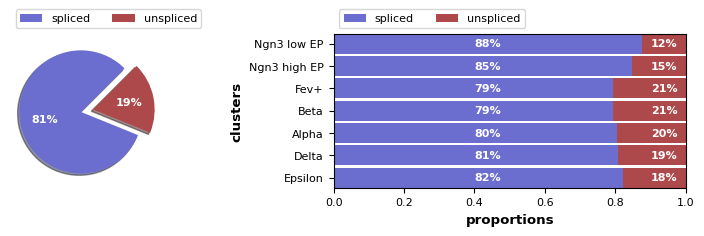

AnnData object with n_obs × n_vars = 2531 × 27998
    obs: 'day', 'proliferation', 'G2M_score', 'S_score', 'phase', 'clusters_coarse', 'clusters', 'clusters_fine', 'louvain_Alpha', 'louvain_Beta', 'palantir_pseudotime'
    var: 'highly_variable_genes'
    uns: 'clusters_colors', 'clusters_fine_colors', 'day_colors', 'louvain_Alpha_colors', 'louvain_Beta_colors', 'neighbors', 'pca'
    obsm: 'X_pca', 'X_umap'
    layers: 'spliced', 'unspliced'
    obsp: 'connectivities', 'distances'

In [8]:
adata = scv.read(r"C:\Users\joshu\Desktop\RNA_Velocity_R\DeepVelo\Cell Rank Tutorials\datasets\endocrinogenesis_day15.5.h5ad")
scv.pl.proportions(adata)
adata

In [11]:
# filter and normalize using scvelo
scv.pp.filter_genes(adata, min_shared_counts = 20)
scv.pp.normalize_per_cell(adata)

# Log transform and hvg
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes = 2000)

# Pca, neighbors, and moments
sc.tl.pca(adata)
sc.pp.neighbors(adata, n_pcs = 30, n_neighbors = 30, random_state= 0)
scv.pp.moments(adata, n_pcs = None, n_neighbors = None)

Filtered out 219 genes that are detected 20 counts (shared).
computing moments based on connectivities
    finished (0:00:01) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)


In [ ]:
configs = {
    "name": "CellRank_DeepVelo", # name of the experiment
    "loss": {"args": {"coeff_s": autoset_coeff_s(adata)}},
    "trainer": {"verbosity": 0}, # increase verbosity to show training progress
}
configs = update_dict(Constants.default_configs, configs)

The ratio of spliced reads is 81.4% (between 70% and 85%). Suggest using coeff_s 0.75.


In [14]:
scv.tl.recover_dynamics(adata, n_jobs = 4)

recovering dynamics (using 4/8 cores)


  0%|          | 0/1019 [00:00<?, ?gene/s]

    finished (0:02:55) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)


c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\scvelo\tools\dynamical_model.py:721: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  np.array([dm.alpha, dm.beta, dm.gamma, dm.pars[:3]]) / dm.m[-1]
c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\scvelo\tools\dynamical_model.py:724: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  np.array([dm.t, dm.tau, dm.t_, dm.pars[4]]) * dm.m[-1]


In [15]:
velocity(adata, mask_zero = False)
trainer = train(
    adata,
    configs
)

computing velocities
    finished (0:00:01) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
Config Warning: Set to use GPU, but GPU version of DGL is not installed. Reset to use CPU instead.
building graph


c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\dgl\base.py:45: DGLWarning: Recommend creating graphs by `dgl.graph(data)` instead of `dgl.DGLGraph(data)`.
  return warnings.warn(message, category=category, stacklevel=1)
INFO:train:Beginning training of DeepVelo ...


velo data shape: torch.Size([2531, 5755])


c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\torch\amp\autocast_mode.py:198: UserWarning: User provided device_type of 'cuda', but CUDA is not available. Disabling
  warnings.warn('User provided device_type of \'cuda\', but CUDA is not available. Disabling')
c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\torch\amp\autocast_mode.py:198: UserWarning: User provided device_type of 'cuda', but CUDA is not available. Disabling
  warnings.warn('User provided device_type of \'cuda\', but CUDA is not available. Disabling')
c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\torch\amp\autocast_mode.py:198: UserWarning: User provided device_type of 'cuda', but CUDA is not available. Disabling
  warnings.warn('User provided device_type of \'cuda\', but CUDA is not available. Disabling')
c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\torch\amp\autocast_mode.py:198: UserWarning: User provided device_type of 'cuda', but CUDA is not available. D

confidence mse shape: (2531, 5755)
confidence mse stats: max 16689.453125, min 0.0, mean 0.520677387714386, std 25.900300979614258
confidence corr shape: (5755,)
confidence corr stats: max 0.8128095865249634, min -0.06737025827169418, mean 0.5380331873893738, std 0.12105047702789307
velo_mat shape: (2531, 5755)
--> added 'velocity' (adata.layers)
--> added 'velocity_unspliced' (adata.layers)
--> added 'cell_specific_beta' (adata.layers)
--> added 'cell_specific_gamma' (adata.layers)


In [16]:
vk = cr.kernels.VelocityKernel(adata)

In [17]:
vk.compute_transition_matrix()

  0%|          | 0/2531 [00:00<?, ?cell/s]

  0%|          | 0/2531 [00:00<?, ?cell/s]

VelocityKernel[n=2531, model='deterministic', similarity='correlation', softmax_scale=6.903]

In [18]:
ck = cr.kernels.ConnectivityKernel(adata)
ck.compute_transition_matrix()

combined_kernel = 0.8 * vk + 0.2 * ck

In [19]:
print(combined_kernel)

(0.8 * VelocityKernel[n=2531] + 0.2 * ConnectivityKernel[n=2531])


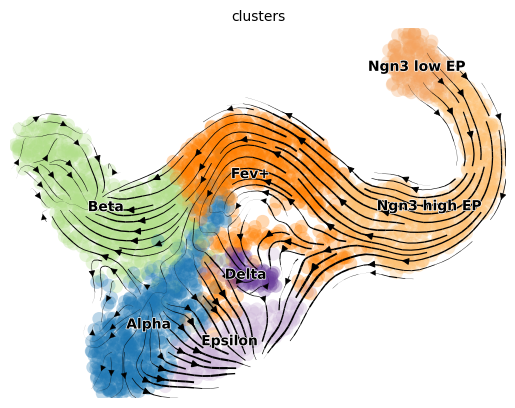

In [20]:
vk.plot_projection()

  0%|          | 0/100 [00:00<?, ?sim/s]

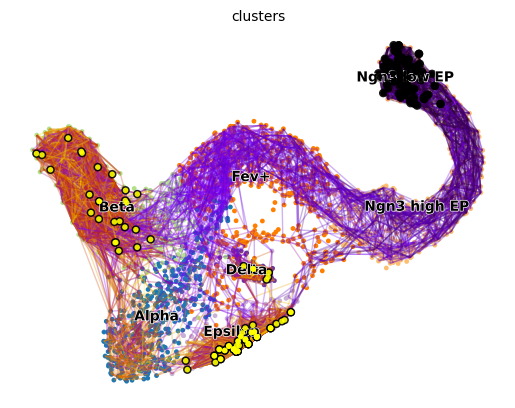

In [21]:
vk.plot_random_walks(
    start_ixs={"clusters": "Ngn3 low EP"},
    max_iter=200,
    seed=0,
    legend_loc="on data",
    color="clusters",
)

In [22]:
adata.write_h5ad("deepvelo_trained_cell.h5ad")